In [24]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy.special
from scipy.special import factorial

# The below commands make the font and image size bigger
plt.rcParams.update({'font.size': 18})
plt.rcParams["figure.figsize"] = (16,9)



In [25]:
def ehrenfest_model(N, t_max, t_step):
    pstate = np.zeros(N)
    time_points = np.arange(0, t_max, t_step)                # x-axis for plotting
    left_points = []                                            # empty array for left y-values
    right_points = []                                           # empty array for right y-values
    entropy = []

    for i in range(t_max):
        n = np.count_nonzero(pstate == 0)                       # keeps track of # particles on the left
        n_right = np.count_nonzero(pstate)                      # keeps track of # particles on the right
        e_coeff =  scipy.special.binom(N, n)

        left_points.append(n)
        right_points.append(n_right)
        entropy.append(e_coeff)
    
        r = np.random.randint(2)
        x = np.where(pstate == r)[0]
    
        if np.size(x) != 0:
            rnd = np.random.choice(x)
            pstate[rnd] = 1 - pstate[rnd]

    return n, n_right, time_points, left_points, right_points, N

<function ehrenfest_model at 0x000002057A83DF30>
Final count of particles on the left: 94
Final count of particles on the right: 6
The standard deviation of the fluctuations is: 5.0


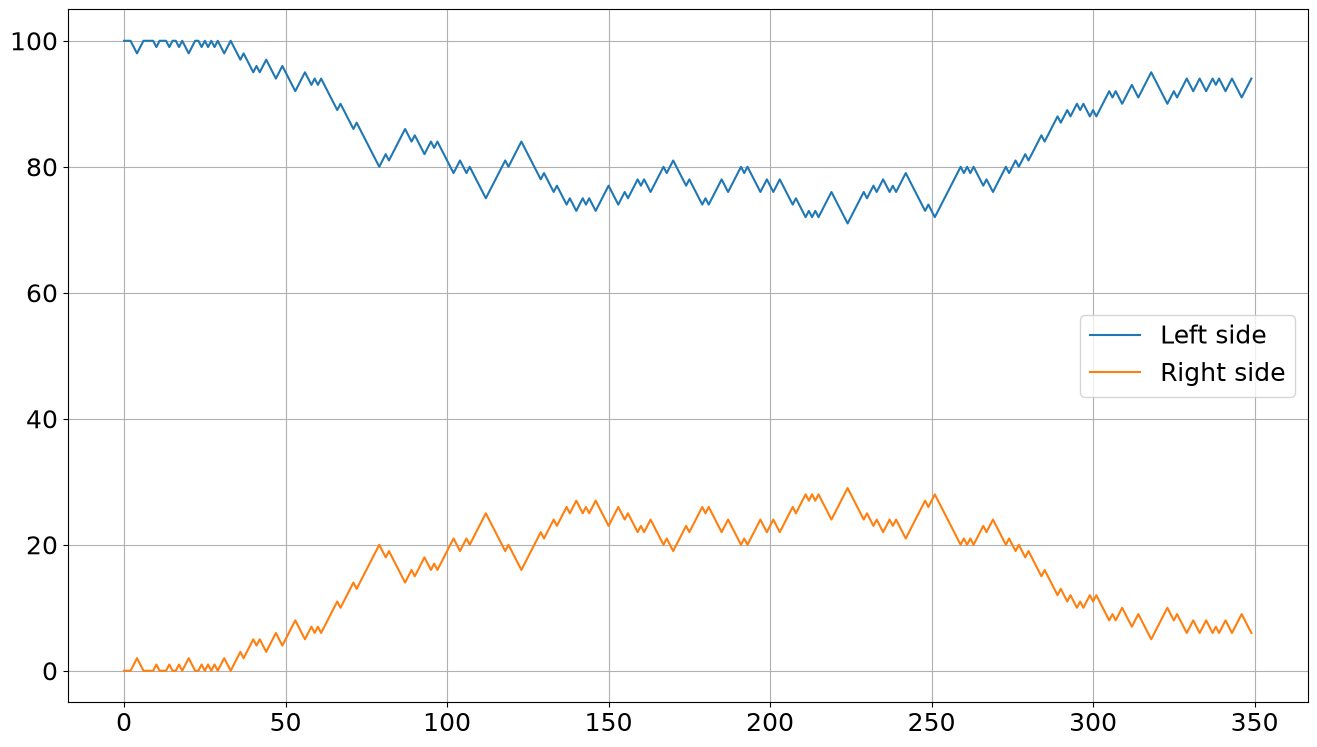

In [31]:
n, n_right, time_points, left_points, right_points, N = ehrenfest_model(100, 350, 1)
print(ehrenfest_model)

# print(pstate)
print("Final count of particles on the left:", n)
print("Final count of particles on the right:", n_right)
print("The standard deviation of the fluctuations is:", np.sqrt(N)/2)

# Plotting
plt.plot(time_points, left_points)
plt.plot(time_points, right_points)
#plt.plot(time_points, (N / 2) * (1 + np.exp((-2*time_points) / N)))
plt.grid(True)
plt.legend(['Left side', 'Right side'])